# Truchet Weave

**Author:** Iman Mossavat · Fontys ICT

## What creates a Truchet weave?

Truchet tiles are simple square pieces with curves that connect points on their edges. By assigning a random orientation to each tile and a color based on a smooth field, simple pieces combine into woven ribbons.

![Final Truchet weave artwork](../truchet_weave.png)


In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from math_vis import make_cmap, smooth_field, squash, finish, TILE_TEXT, parse_tile, rotate_tile, tile_curve

SEED = 7
NX, NY = 10, 12
N_STRANDS = 3
BAND = 0.055
STRAND_SHIFT = 0.09
ORIENT_SMOOTH = 1.2
COLOR_SMOOTH = 3.0
JITTER = 0.04
BG = '#f1e9d2'

rng = np.random.default_rng(SEED)
palette = make_cmap(['#d9674a', '#e8a56b', '#e6d28f', '#9db08c', '#5f8a86', '#2c3a35'])

## The tile library

These 14 tiles are all the non-crossing ways to pair the four edge points of a square. Every tile is simple on its own; the complexity comes from choosing one rotation per grid cell.

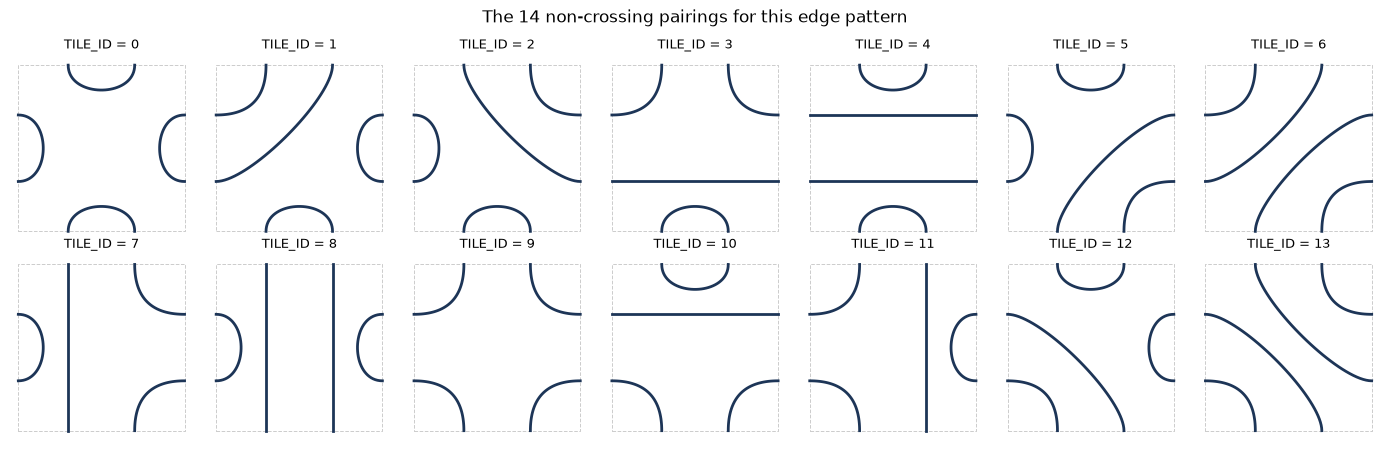

In [2]:
# 1. Show the tile library
tiles = [parse_tile(t) for t in TILE_TEXT]
fig, axes = plt.subplots(2, 7, figsize=(14, 4.6))
for k, ax in enumerate(axes.ravel()):
    ax.plot([0,1,1,0,0], [0,0,1,1,0], color='#ccc', lw=0.7, ls='--')
    for i, j in tiles[k]:
        c = tile_curve(i, j)
        ax.plot(c[:,0], c[:,1], color='#1d3557', lw=2)
    ax.set_title(f'TILE_ID = {k}', fontsize=9)
    ax.set_aspect('equal'); ax.axis('off')
plt.suptitle('The 14 non-crossing pairings for this edge pattern', fontsize=12)
plt.tight_layout(); plt.show()

> **Question:** Why is it important that the curves do *not* cross inside a tile? What would happen to the ribbons if they did?

## Two smooth fields

One field decides whether a tile is rotated. A second, smoother field decides the color. Because both fields are spatially coherent, nearby tiles tend to share orientations and colors.

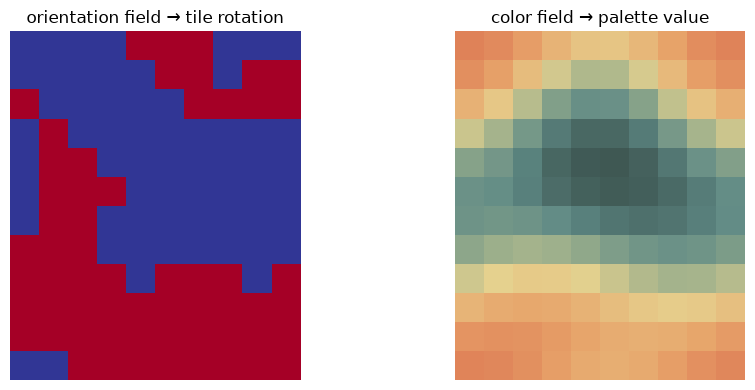

In [3]:
# 2. Orientation field and color field
orient_field = smooth_field((NY, NX), ORIENT_SMOOTH, rng)
color_field = smooth_field((NY, NX), COLOR_SMOOTH, rng)

fig, axs = plt.subplots(1, 2, figsize=(10, 4))
im1 = axs[0].imshow((orient_field > 0).astype(int), cmap='RdYlBu', origin='lower', extent=(0,NX,0,NY))
axs[0].set_title('orientation field → tile rotation'); axs[0].axis('off')
im2 = axs[1].imshow(squash(color_field), cmap=palette, vmin=0, vmax=1, origin='lower', extent=(0,NX,0,NY))
axs[1].set_title('color field → palette value'); axs[1].axis('off')
plt.tight_layout(); plt.show()

> **Question:** If `COLOR_SMOOTH` were much smaller than `ORIENT_SMOOTH`, would the colors or the orientations change faster across the grid?

## Building the weave

Each tile curve is shifted outward along its normal to create multiple strands. The color is sampled once per tile and tinted slightly for each strand.

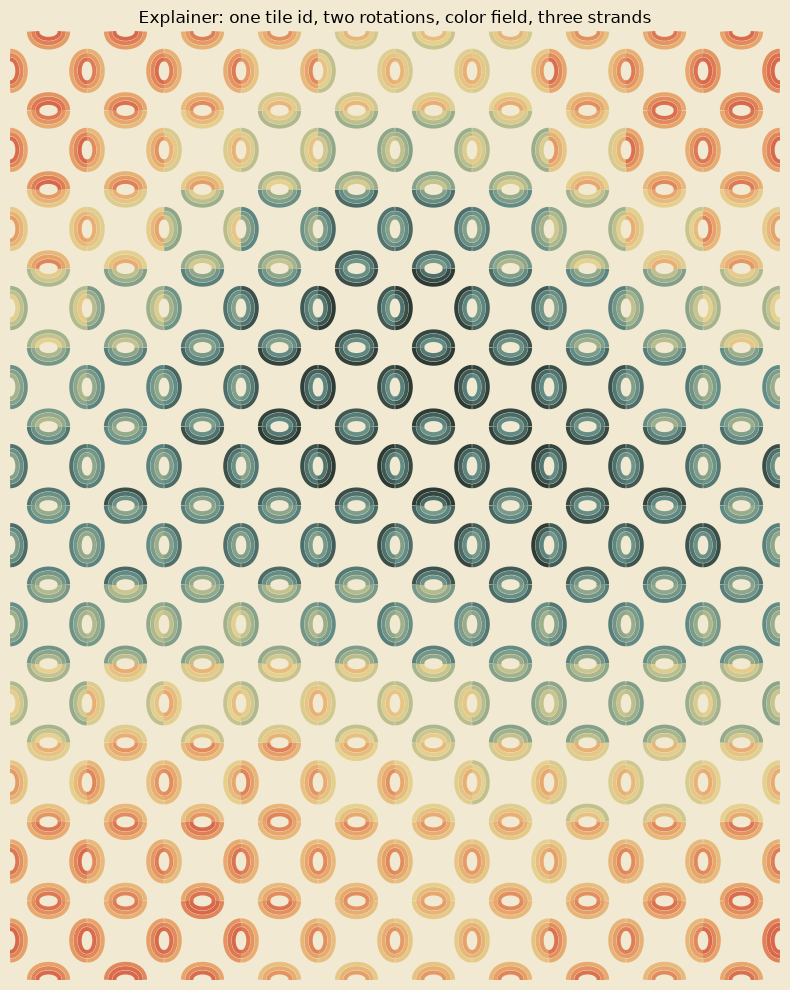

In [4]:
# 3. Combine: draw all tiles with color and strands
rotations = [0, 1]
def to_index(field, n):
    if n == 1: return np.zeros(field.shape, dtype=int)
    cuts = np.quantile(field, np.linspace(0, 1, n+1)[1:-1])
    return np.digitize(field, cuts)

rot_idx = to_index(orient_field, len(rotations))
offsets = np.linspace(-1, 1, N_STRANDS) if N_STRANDS > 1 else np.array([0.0])
strand_w = BAND * (8 * 72 / NX) * 0.9

segments, colors = [], []
for j in range(NY):
    for i in range(NX):
        tile = rotate_tile(tiles[0], rotations[rot_idx[j, i]])
        for a, b in tile:
            base = tile_curve(a, b) + [i, j]
            t = squash(color_field[j, i]) + rng.normal(0, JITTER)
            tang = np.gradient(base, axis=0)
            tang /= np.linalg.norm(tang, axis=1, keepdims=True)
            for off in offsets:
                seg = base + off * BAND * (N_STRANDS-1)/2 * np.column_stack([-tang[:,1], tang[:,0]])
                segments.append(seg)
                colors.append(palette(np.clip(t + off * STRAND_SHIFT, 0, 1)))

fig, ax = plt.subplots(figsize=(8, 10), facecolor=BG)
ax.set_facecolor(BG)
ax.set_xlim(0, NX); ax.set_ylim(0, NY); ax.axis('off')
ax.add_collection(LineCollection(segments, colors=colors, linewidths=strand_w, capstyle='butt'))
ax.set_title('Explainer: one tile id, two rotations, color field, three strands')
plt.tight_layout(); plt.show()

> **Question:** What visual effect does increasing `N_STRANDS` have? Does it make the pattern look more like cloth, or more like tile lines?

## Experiments

Try changing `NX`, `NY`, `N_STRANDS`, `BAND`, `ORIENT_SMOOTH`, or `COLOR_SMOOTH`. Predict how each change affects the density, width, or color variation of the ribbons.

seed: 7


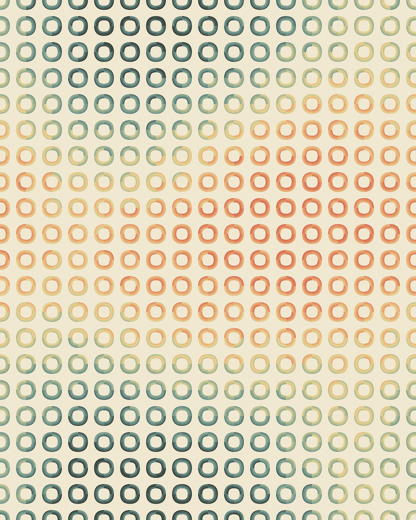

In [5]:
# 4. Final render with the package function
from math_vis import render_truchet_weave
img = render_truchet_weave(seed=SEED, nx=16, ny=20, n_strands=3, grain=3)
final = finish(img, name='truchet_weave.png', display=False)
from IPython.display import display
from PIL import Image
preview = Image.fromarray(final).resize((416, 520))
display(preview)

## What did we learn?

- A small tile library can generate complex patterns when repeated.
- Two smooth fields can control different aspects: orientation and color.
- Shifting strands along normals creates the illusion of weaving.

**Open questions:**
1. What would happen if tiles could also be mirrored, not just rotated?
2. How would the pattern change if the color field had much larger features than the orientation field?

**Further experiment:** Try `N_STRANDS=1` versus `N_STRANDS=5`. How does strand count affect the woven look?